In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from datetime import datetime
from torchvision import datasets, models, transforms
from torchsummary import summary
from torch.utils.data import Dataset

import numpy as np
import matplotlib.pyplot as plt
import time
import os
import copy
from sklearn import metrics

## Objetivo da Prática de Laboratório – Treinamento de Classificadores com CNNs

<p>O objetivo desta prática é capacitar os alunos a compreender e aplicar os principais conceitos relacionados ao treinamento de classificadores de imagens utilizando redes neurais convolucionais (CNNs), com foco especial em estratégias de fine-tuning e treinamento a partir do zero (from scratch).</p>

<p>Durante a atividade, os alunos irão:
<ul>

<li>Utilizar uma CNN pré-treinada em uma base conhecida (base Intel Image Classification) para realizar tarefas de classificação de cenas naturais;</li>
<li>Aplicar duas abordagens de fine-tuning:</li>
  <ol>
  <li>Congelamento das camadas convolucionais iniciais e ajuste apenas das camadas finais;</li>
  <li>Carregamento dos pesos pré-treinados e ajuste de toda a rede (sem congelamento);</li>
  </ol>
<li>Comparar os resultados com um modelo treinado do zero (sem uso de pesos pré-treinados);</kli>
<li>Explorar técnicas de processamento de imagens, como:</li>
  <ol>
  <li>Aumento de dados (Data Augmentation): aplicação de transformações geométricas e fotométricas (como rotações, flips, zooms, ajustes de brilho/contraste) com o objetivo de aumentar a variabilidade dos dados de entrada e melhorar a capacidade de generalização do modelo;</li>
  <li>Normalização e redimensionamento de imagens como parte do pré-processamento;</li>
  </ol>
<li>Analisar a capacidade das CNNs de realizar extração automática de características, dispensando a necessidade de engenharia manual de atributos — um diferencial em relação a métodos tradicionais de PDI.</li>
</ul>
</p>

<p>Na segunda parte da prática, os alunos aplicarão os conhecimentos adquiridos para treinar modelos (com fine-tuning e do zero) em uma base de lesões de pele (como o Melanoma Skin Cancer Dataset), analisando os desafios particulares relacionados à variabilidade das lesões, possível desbalanceamento de classes, e importância clínica da tarefa de classificação.</p>

## Funções de treino e predição

In [ ]:
def fit(model, criterion, optimizer, train_loader, test_loader, epochs):
    train_losses = np.zeros( epochs )
    test_losses = np.zeros( epochs )

    for it in range(epochs):
        model.train()
        t0 = datetime.now()
        train_loss = []

        for inputs, targets in train_loader:
            # mover os dados para o GPU
            inputs, targets = inputs.to(device), targets.to(device)

            # zerar os gradientes
            optimizer.zero_grad()

            # forward pass
            outputs = model(inputs)

            loss = criterion(outputs, targets)

            # backward pass e optimiza
            loss.backward()
            optimizer.step()

            train_loss.append( loss.item() )

        train_loss = np.mean(train_loss)

        test_loss = []
        for inputs, targets in test_loader:
            model.eval()
            # mover os dados para o GPU
            inputs, targets = inputs.to(device), targets.to(device)

            # forward pass
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            test_loss.append(loss.item())
        test_loss = np.mean(test_loss)

        # salvar losses
        train_losses[it] = train_loss
        test_losses[it] = test_loss

        dt = datetime.now() - t0

        print(f'Epoch {it+1}/{epochs} Train Loss: {train_loss:.4f} Test Loss: {test_loss} Duracao: {dt}')

    return train_losses, test_losses

In [ ]:
def predict_module(model, test_loader):
    model.eval()
    predicted = np.empty((0), int)
    true_labels = np.empty((0), int)
    for inputs, targets in test_loader:
        # mover os dados para o GPU
        inputs, targets = inputs.to(device), targets.to(device)

        outputs = model(inputs)

        # obter a predição
        _, predictions = torch.max(outputs, 1)

        predicted = np.append(predicted, predictions.cpu())
        true_labels = np.append(true_labels, targets.cpu())

    return predicted, true_labels

### Função que grafica as funções de perda(custo) do treino e da validação

In [ ]:
def plot_losses(train_losses, test_losses):
    plt.plot(train_losses, label = 'train loss')
    plt.plot(test_losses, label = 'test loss')
    plt.legend()
    plt.show()

### Matriz de Confusão

In [ ]:
def matriz_confusao(true_labels, predicted, display_labels=[0,1,2]):
    matriz = metrics.confusion_matrix(true_labels, predicted)
    tot = np.sum(matriz, axis=1, keepdims=True)
    np.set_printoptions(precision=2)
    m_porc = matriz/tot
    disp = metrics.ConfusionMatrixDisplay(confusion_matrix=m_porc, display_labels=display_labels)
    disp.plot(values_format='.2f', xticks_rotation='vertical')
    plt.show()

# Dataset 1

### Treinamento a partir de uma base propria de imagens - Intel Image Classification
<p>
Context: This is image data of Natural Scenes around the world.
</p>

<p>
<img src="https://miro.medium.com/v2/resize:fit:786/format:webp/1*Y1y83HN7oI98EJT3LQgv-g.png" alt="Drawing"  width="500"/>

Content: This Data contains around 25k images of size 150x150 distributed under 6 categories.
  <ul>
    <li>buildings</li>
    <li>forest</li>
    <li>glacier</li>
    <li>mountain</li>
    <li>sea</li>
    <li>street</li>
  </ul>
</p>

<p>
Fonte: <a href="https://www.kaggle.com/datasets/puneet6060/intel-image-classification">Intel Image Classification</a>
</p>


### Usar Gdown para realizar a descarga de um arquivo desde o drive

In [ ]:
# instalação da biblioteca gdown
!pip install gdown

In [ ]:
# importando a biblioteca
import gdown

### Cómo utilizar?
<img src="https://drive.google.com/uc?id=1VgEEHaw-5798fIY03iWIYOIYK4-kkiNW" alt="Drawing"  width="900"/>

```
gdown --id <put-the-ID>
```

In [ ]:
# Realizando a descarga do Intel Dataset usando o id do gdrive do arquivo
!gdown --id 16oJl8kDIBMvKdeAkCqXrmZCQMi9lb8ft

/usr/local/lib/python3.11/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=16oJl8kDIBMvKdeAkCqXrmZCQMi9lb8ft
From (redirected): https://drive.google.com/uc?id=16oJl8kDIBMvKdeAkCqXrmZCQMi9lb8ft&confirm=t&uuid=2e2ec08a-ea14-495a-8e93-492d983c989d
To: /content/dataset.zip
100% 253M/253M [00:02<00:00, 84.5MB/s]


In [ ]:
# biblioteca para descomprimir o arquivo zip
import zipfile
import os

In [ ]:
# funçao que realiza a descompressão do arquivo
def unzip_dataset(filename, directory):
  """
  filename: nome do arquivo, incluir o endereço onde está localizado o arquivo
  directory: pasta onde será decomprimido o arquivo
  """
  zip_ref = zipfile.ZipFile(filename, 'r')
  zip_ref.extractall(directory)
  zip_ref.close()

### Descomprimir arquivo zip

In [ ]:
# Top level data directory. Here we assume the format of the directory conforms
#   to the ImageFolder structure
data_dir = '/content/data/Intel/'
unzip_dataset(filename='/content/dataset.zip', directory=data_dir )

In [ ]:
%ls /content/data/Intel/
%ls /content/data/Intel/test

test/  train/
buildings/  forest/  glacier/  mountain/  sea/  street/


### Transformações geométricas nas imagens

In [ ]:
# esse é o tamanho da imagem de entrada da CNN treinada que vamos usar
input_size = 224
# Aumento e normalização de dados para treinamento
# Apenas normalização para validação
data_transforms = {
    'train': transforms.Compose([
        #transforms.Resize(size=(input_size,input_size)),
        #transforms.CenterCrop(input_size),
        transforms.RandomResizedCrop(input_size),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(size=(input_size,input_size)),
        transforms.CenterCrop(input_size),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

### Classe Dataset usando ImageFolder

In [ ]:
print("Incializando Datasets ...")

# Criar conjuntos de dados de treinamento e validação
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'test']}

# image_datasets é um dicionario com as chaves 'train' e 'test'
print(image_datasets)

Incializando Datasets ...
{'train': Dataset ImageFolder
    Number of datapoints: 14034
    Root location: /content/data/Intel/train
    StandardTransform
Transform: Compose(
               RandomResizedCrop(size=(224, 224), scale=(0.08, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           ), 'test': Dataset ImageFolder
    Number of datapoints: 3000
    Root location: /content/data/Intel/test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               CenterCrop(size=(224, 224))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )}


In [ ]:
image_datasets.keys()

dict_keys(['train', 'test'])

### Particionar o conjunto de treino em treino e validacão

In [ ]:
# conjunto de treino é divido em treino (80%) e validação (20%)
train_dataset_split, val_dataset_split = torch.utils.data.random_split(image_datasets['train'], [0.8, 0.2])

# é adicionado no dicionario image_datasets o conjunto de validação e o conjunto de treino é atualizado
image_datasets['val'] = val_dataset_split
image_datasets['train'] = train_dataset_split

### Definição dos Dataloaders

In [ ]:
# Batch size for training (change depending on how much memory you have)
batch_size = 64

# Criar dataloaders de treinamento e validação
dataloaders_dict = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=batch_size, shuffle=True, num_workers=2) for x in ['train', 'val','test']}

## Fine-tuning

### Função que congela ou descongela as camadas de uma rede

<p> Por *default* são carregadas descongeladas, ou seja, permite que todos os pesos da rede sejam atualizados durante o treino.</p>

In [ ]:
def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

## Definição da redes

### Rede MLP (Multi Layer Perceptron)

In [ ]:
def make_layers(cfg, in_channels = 3):
    layers = []
    for v in cfg:
        layers += [nn.Linear(in_channels, v), nn.ReLU()]
        in_channels = v
    return nn.Sequential(*layers)

In [ ]:
class MeuMLP(nn.Module):
    def __init__(self,entrada=4,camadas_escondidas=256 ,saida=3):
        super(MeuMLP, self).__init__()
        self.hidden_layers_num = camadas_escondidas
        self.dense_hidden = make_layers(self.hidden_layers_num, entrada)
        self.fc = nn.Linear(self.hidden_layers_num[-1], saida)

    def forward(self, x):
        x = self.dense_hidden(x)
        x = self.fc(x)
        return x

### Rede que implementa o Fine-tuning

In [ ]:
class FineTuningNetwork(nn.Module):
    def __init__(self, backbone, classifier):
        super(FineTuningNetwork, self).__init__()
        self.backbone = backbone
        self.classifier = classifier

    def forward(self, x):
        # Passa os dados pelo backbone (CNN pré-treinada)
        features = self.backbone(x)

        # Passa as características extraídas pelo classificador (MLP)
        out = self.classifier(features)
        return out

### Finetuning com a rede VGG11

### Questão 1: Fine tuning, congelando as camadas

In [ ]:
# Carrega a CNN VGG11 e os pesos treinados com a base Imagenet
backbone = models.vgg11(weights='VGG11_Weights.DEFAULT')
print(backbone)

Downloading: "https://download.pytorch.org/models/vgg11-8a719046.pth" to /root/.cache/torch/hub/checkpoints/vgg11-8a719046.pth
100%|██████████| 507M/507M [00:07<00:00, 75.2MB/s]


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU(inplace=True)
    (13): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
 

In [ ]:
# Remover a última camada totalmente conectada (classifier)
backbone = nn.Sequential(*list(backbone.children())[:-1])

# Adicionar uma camada de flatten (conversão para vetor)
backbone.add_module("flatten", nn.Flatten())

# Criar as camadas para classificação
classificador = MeuMLP(entrada=25088, camadas_escondidas=[256, 128, 64, 32] , saida=6 )

In [ ]:
# instanciar a rede passando o backbone (nossa VGG16) e o classifier
model = FineTuningNetwork(backbone=backbone, classifier=classificador)

# loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

# Congelar as camadas do backbone para não treinar novamente
set_parameter_requires_grad(backbone, feature_extracting=True)

Epoch 1/5 Train Loss: 0.4807 Test Loss: 0.4385228496976197 Duracao: 0:00:45.350613
Epoch 2/5 Train Loss: 0.3766 Test Loss: 0.3668476464226842 Duracao: 0:00:44.320400
Epoch 3/5 Train Loss: 0.3423 Test Loss: 0.3662276750599796 Duracao: 0:00:43.400364
Epoch 4/5 Train Loss: 0.3274 Test Loss: 0.38748292285758495 Duracao: 0:00:42.814078
Epoch 5/5 Train Loss: 0.3083 Test Loss: 0.32255664586343546 Duracao: 0:00:43.813142


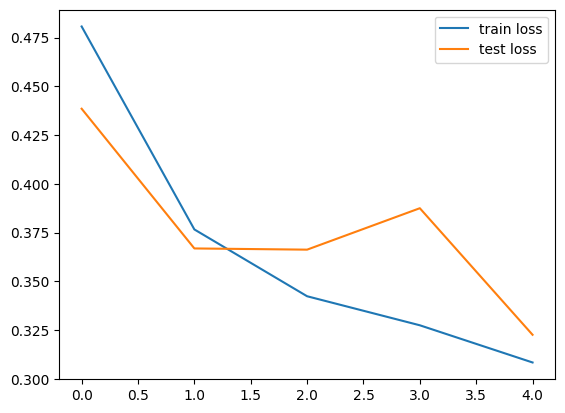

In [ ]:
# verificar disponibilidade de placa de vídeo
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

# treinar
train_losses, test_losses = fit(model, criterion, optimizer, dataloaders_dict['train'], dataloaders_dict['val'], epochs = 5)
plot_losses(train_losses, test_losses)

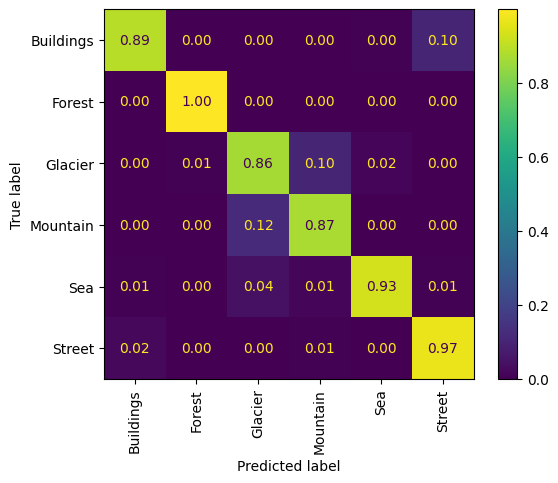

In [ ]:
# Avaliando com o conjunto de teste
predicted, true_labels = predict_module(model, dataloaders_dict['test'])
matriz_confusao(true_labels, predicted, ['Buildings', 'Forest', 'Glacier', 'Mountain', 'Sea', 'Street'])

## Questão 2: Finetuning sem congelar camadas

In [ ]:
# Carrega a CNN VGG11 e os pesos treinados com a base Imagenet
backbone2 = models.vgg11(weights='VGG11_Weights.DEFAULT')

# Remover a última camada totalmente conectada (classifier)
backbone2 = nn.Sequential(*list(backbone2.children())[:-1])

# Adicionar uma camada de flatten (conversão para vetor)
backbone2.add_module("flatten", nn.Flatten())

# Criar as camadas para classificação
classificador2 = MeuMLP(entrada=25088, camadas_escondidas=[256, 128, 64, 32] , saida=6 )

In [ ]:
# instanciar a rede passando o backbone (nossa VGG16) e o classifier
model2 = FineTuningNetwork(backbone=backbone2, classifier=classificador2)

# loss and optimizer
criterion2 = nn.CrossEntropyLoss()
optimizer2 = torch.optim.Adam(model2.parameters())

Epoch 1/10 Train Loss: 1.2161 Test Loss: 1.1064824343404986 Duracao: 0:01:25.757988
Epoch 2/10 Train Loss: 1.0000 Test Loss: 0.8598064204508608 Duracao: 0:01:24.976200
Epoch 3/10 Train Loss: 0.8709 Test Loss: 0.8286230321973562 Duracao: 0:01:25.369975
Epoch 4/10 Train Loss: 0.7534 Test Loss: 0.7061835883862593 Duracao: 0:01:25.842262
Epoch 5/10 Train Loss: 0.7423 Test Loss: 0.6615627673877911 Duracao: 0:01:25.560158
Epoch 6/10 Train Loss: 0.6926 Test Loss: 0.7700164031914689 Duracao: 0:01:25.428043
Epoch 7/10 Train Loss: 0.6597 Test Loss: 0.6078689313409004 Duracao: 0:01:24.587284
Epoch 8/10 Train Loss: 0.6473 Test Loss: 0.6757528898729519 Duracao: 0:01:25.203100
Epoch 9/10 Train Loss: 0.6516 Test Loss: 0.7211493060670116 Duracao: 0:01:25.232122
Epoch 10/10 Train Loss: 0.6172 Test Loss: 0.5813486929982901 Duracao: 0:01:25.451637


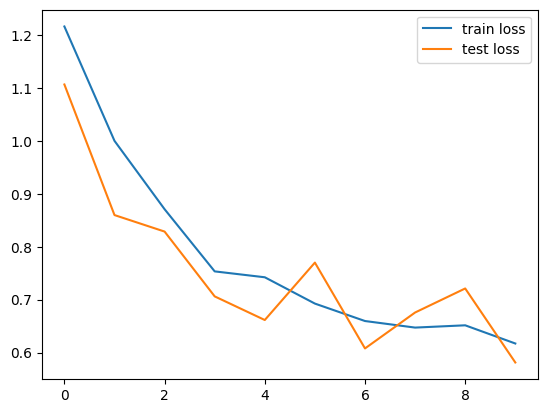

In [ ]:
model2.to(device)

# treinar
train_losses, test_losses = fit(model2, criterion2, optimizer2, dataloaders_dict['train'], dataloaders_dict['val'], epochs = 10)
plot_losses(train_losses, test_losses)

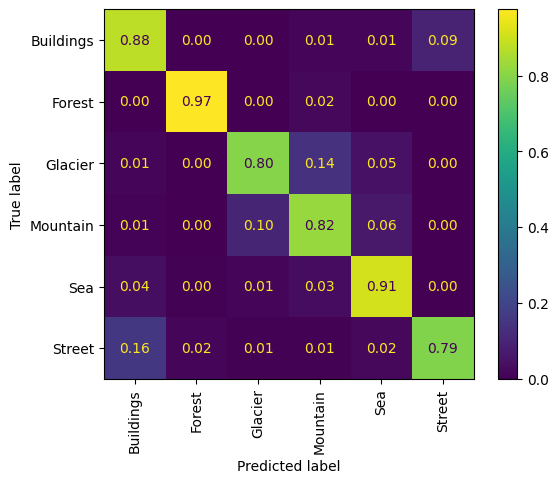

In [ ]:
# Avaliando com o conjunto de teste
predicted, true_labels = predict_module(model2, dataloaders_dict['test'])
matriz_confusao(true_labels, predicted, ['Buildings', 'Forest', 'Glacier', 'Mountain', 'Sea', 'Street'])

## Questão 3: From scratch

In [ ]:
# Carrega a CNN VGG11 e os pesos treinados com a base Imagenet
backbone3 = models.vgg11()

# Remover a última camada totalmente conectada (classifier)
backbone3 = nn.Sequential(*list(backbone3.children())[:-1])

# Adicionar uma camada de flatten (conversão para vetor)
backbone3.add_module("flatten", nn.Flatten())

# Criar as camadas para classificação
classificador3 = MeuMLP(entrada=25088, camadas_escondidas=[256, 128, 64, 32] , saida=6 )

In [ ]:
# instanciar a rede passando o backbone (nossa VGG16) e o classifier
model3 = FineTuningNetwork(backbone=backbone3, classifier=classificador3)

# loss and optimizer
criterion3 = nn.CrossEntropyLoss()
optimizer3 = torch.optim.Adam(model3.parameters())

Epoch 1/10 Train Loss: 1.3977 Test Loss: 1.1090339801528237 Duracao: 0:01:24.373724
Epoch 2/10 Train Loss: 1.1090 Test Loss: 1.016653833064166 Duracao: 0:01:23.056161
Epoch 3/10 Train Loss: 1.0102 Test Loss: 1.0160961625250904 Duracao: 0:01:23.023944
Epoch 4/10 Train Loss: 0.9211 Test Loss: 0.8938893269408833 Duracao: 0:01:22.642144
Epoch 5/10 Train Loss: 0.8131 Test Loss: 0.7361413910984993 Duracao: 0:01:23.664277
Epoch 6/10 Train Loss: 0.7582 Test Loss: 0.7695893753658641 Duracao: 0:01:22.916508
Epoch 7/10 Train Loss: 0.7196 Test Loss: 0.8521158966151151 Duracao: 0:01:22.508607
Epoch 8/10 Train Loss: 0.6826 Test Loss: 0.6614486873149872 Duracao: 0:01:23.310619
Epoch 9/10 Train Loss: 0.6427 Test Loss: 0.6559153774922545 Duracao: 0:01:23.067150
Epoch 10/10 Train Loss: 0.6370 Test Loss: 0.6656613675030795 Duracao: 0:01:22.342623


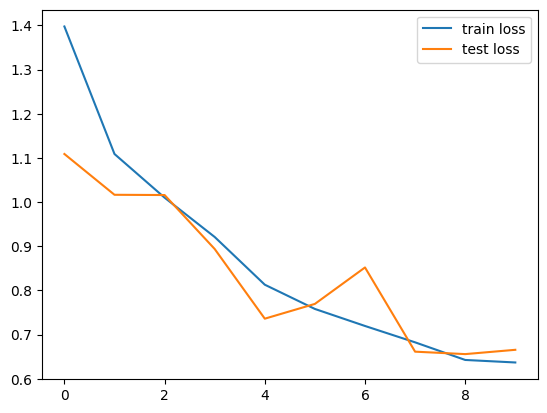

In [ ]:
model3.to(device)

# treinar
train_losses, test_losses = fit(model3, criterion3, optimizer3, dataloaders_dict['train'], dataloaders_dict['val'], epochs = 10)
plot_losses(train_losses, test_losses)

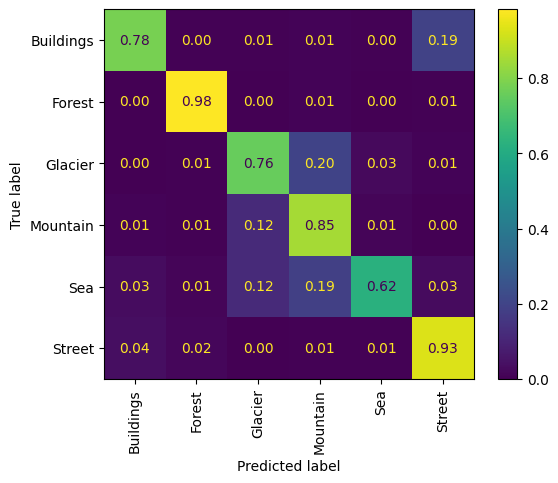

In [ ]:
# Avaliando com o conjunto de teste
predicted, true_labels = predict_module(model3, dataloaders_dict['test'])
matriz_confusao(true_labels, predicted, ['Buildings', 'Forest', 'Glacier', 'Mountain', 'Sea', 'Street'])

# Dataset 2

### Treinamento a partir de uma base propria de imagens - Melanoma Skin Cancer Dataset of 10000 Images
<p>
A base Melanoma Skin Cancer Dataset of 10000 Images, disponível no Kaggle e desenvolvida por Muhammad Hasnain Javid, apresenta um repositório composto por aproximadamente 10 000 imagens de lesões cutâneas, categorizadas em duas classes: benign (benigno) e malignant (maligno). Essas imagens têm sido amplamente utilizadas em estudos acadêmicos como recurso de treinamento e avaliação de modelos para classificação de melanom
</p>

<p><img src="https://drive.google.com/uc?id=1m9i3ypm4DJ_ag6Ca66vPM40a26grGhYG" alt="Drawing"  width="500"/></p>



In [ ]:
# Realizando a descarga da base Melanoma Skin Cancer
!gdown --id 1YMSQytG0mLBET5h1Io_y4dLbraQgqF-G

/usr/local/lib/python3.11/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1YMSQytG0mLBET5h1Io_y4dLbraQgqF-G
From (redirected): https://drive.google.com/uc?id=1YMSQytG0mLBET5h1Io_y4dLbraQgqF-G&confirm=t&uuid=776cdf0f-44b2-4655-b735-e55fddeb2824
To: /content/melanoma_cancer.zip
100% 104M/104M [00:01<00:00, 73.6MB/s] 


In [ ]:
data_dir = '/content/data/'
unzip_dataset(filename='/content/melanoma_cancer.zip', directory=data_dir )

### Verifica a disposição dos arquivos

In [ ]:
%ls /content/data/
%ls /content/data/melanoma_cancer_dataset/
%ls /content/data/melanoma_cancer_dataset/test

melanoma_cancer_dataset/
test/  train/
benign/  malignant/


In [ ]:
# esse é o tamanho da imagem de entrada da CNN treinada que vamos usar
input_size = 224
# Aumento e normalização de dados para treinamento
# Apenas normalização para validação
data_transforms = {
    'train': transforms.Compose([
            transforms.RandomRotation(degrees = 20),
            transforms.RandomHorizontalFlip(p = 0.3),
            transforms.RandomVerticalFlip(p = 0.3),
            transforms.Resize(size = (input_size, input_size), antialias = True),
            transforms.CenterCrop(size = (input_size, input_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize(size = (input_size,input_size), antialias = True),
        transforms.CenterCrop(size = (input_size,input_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225])
    ]),
}

### Classe Dataset usando ImageFolder

In [ ]:
print("Incializando Datasets ...")
root = '/content/data/melanoma_cancer_dataset/'
# Criar conjuntos de dados de treinamento e validação

image_datasets = {x: datasets.ImageFolder(os.path.join(root, x), data_transforms[x]) for x in ['train', 'test']}

# image_datasets é um dicionario com as chaves 'train' e 'test'
print(image_datasets)

Incializando Datasets ...
{'train': Dataset ImageFolder
    Number of datapoints: 9605
    Root location: /content/data/melanoma_cancer_dataset/train
    StandardTransform
Transform: Compose(
               RandomRotation(degrees=[-20.0, 20.0], interpolation=nearest, expand=False, fill=0)
               RandomHorizontalFlip(p=0.3)
               RandomVerticalFlip(p=0.3)
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               CenterCrop(size=(224, 224))
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           ), 'test': Dataset ImageFolder
    Number of datapoints: 1000
    Root location: /content/data/melanoma_cancer_dataset/test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               CenterCrop(size=(224, 224))
               ToTensor()
               Normalize(mean=[0.485, 0.456

### Particionar o conjunto de treino em treino e validacão

In [ ]:
# conjunto de treino é divido em treino (80%) e validação (20%)
train_dataset_split, val_dataset_split = torch.utils.data.random_split(image_datasets['train'], [0.8, 0.2])

# é adicionado no dicionario image_datasets o conjunto de validação e o conjunto de treino é atualizado
image_datasets['val'] = val_dataset_split
image_datasets['train'] = train_dataset_split

### Definição dos Dataloaders

In [ ]:
# Batch size for training (change depending on how much memory you have)
batch_size = 64

# Criar dataloaders de treinamento e validação
dataloaders_dict = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=batch_size, shuffle=True, num_workers=2) for x in ['train', 'val','test']}

batch de dados: torch.Size([64, 3, 224, 224])
batch de etiquetas: torch.Size([64])


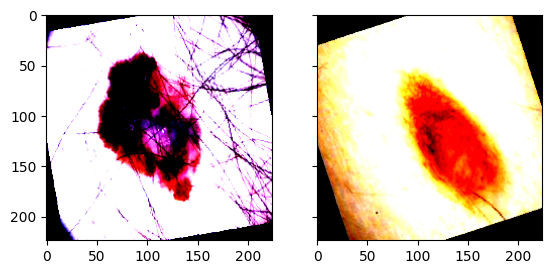

In [ ]:
# verificação do funcionamento do dataloader
for x, y in dataloaders_dict['train']:
    print(f'batch de dados: {x.shape}')
    print(f'batch de etiquetas: {y.shape}')
    f, (ax1, ax2) = plt.subplots(1, 2, sharey=True)
    ax1.imshow(np.transpose(x[0].numpy(), (1,2,0)), cmap = 'gray')
    ax2.imshow(np.transpose(x[1].numpy(), (1,2,0)), cmap = 'gray')
#    ax1.imshow(x[0].numpy()[-1,:,:], cmap = 'gray')
#    ax2.imshow(x[1].numpy()[-1,:,:], cmap = 'gray')
    break

#### Finetuning

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


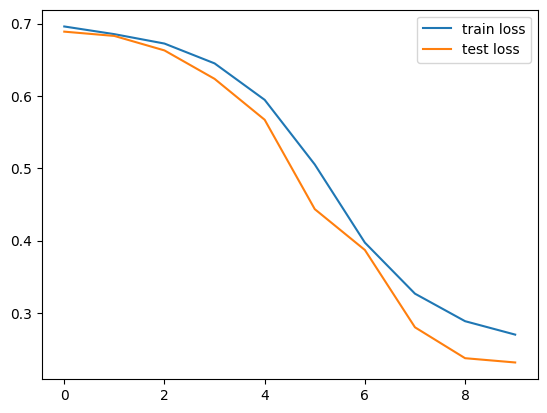

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights

# Carrega a CNN VGG11 e os pesos treinados com a base Imagenet
#backbone = models.vgg11(weights='VGG11_Weights.DEFAULT')
backbone = models.resnet50(weights=ResNet50_Weights.DEFAULT)

# Remover a última camada totalmente conectada (classifier)
backbone = nn.Sequential(*list(backbone.children())[:-1])

# Adicionar uma camada de flatten (conversão para vetor)
backbone.add_module("flatten", nn.Flatten())

print(backbone)

# Criar as camadas para classificação
classificador = MeuMLP(entrada=2048, camadas_escondidas=[256, 16, 8] , saida=2 )

# instanciar a rede passando o backbone (nossa VGG16) e o classifier
model = FineTuningNetwork(backbone=backbone, classifier=classificador)

# loss and optimizer
criterion = nn.CrossEntropyLoss()
#optimizer = torch.optim.Adam(model.parameters())
optimizer = torch.optim.SGD(model.parameters(),
                                    lr=0.001,
                                    momentum=0.9,
                                    weight_decay=1e-3)

# Congelar as camadas do backbone para não treinar novamente
set_parameter_requires_grad(backbone, feature_extracting=True)

# verificar disponibilidade de placa de vídeo
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

# treinar
train_losses, test_losses = fit(model, criterion, optimizer, dataloaders_dict['train'], dataloaders_dict['val'], epochs = 10)
plot_losses(train_losses, test_losses)

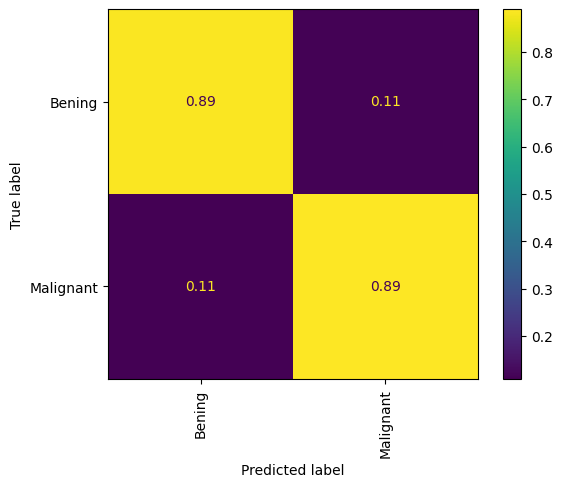

In [ ]:
# Avaliando com o conjunto de teste
predicted, true_labels = predict_module(model, dataloaders_dict['test'])
#matriz_confusao(true_labels, predicted, ['Buildings', 'Forest', 'Glacier', 'Mountain', 'Sea', 'Street'])
matriz_confusao(true_labels, predicted, ['Bening', 'Malignant'])

### From scratch

Epoch 1/10 Train Loss: 0.9660 Test Loss: 0.6892083402602903 Duracao: 0:01:19.699515
Epoch 2/10 Train Loss: 0.5843 Test Loss: 0.4663322331353782 Duracao: 0:01:22.706004
Epoch 3/10 Train Loss: 0.4282 Test Loss: 0.44227179019681867 Duracao: 0:01:22.816033
Epoch 4/10 Train Loss: 0.4074 Test Loss: 0.4490108986295039 Duracao: 0:01:22.488362
Epoch 5/10 Train Loss: 0.3796 Test Loss: 0.38048316213873123 Duracao: 0:01:23.878746
Epoch 6/10 Train Loss: 0.3583 Test Loss: 0.364192737206336 Duracao: 0:01:23.342749
Epoch 7/10 Train Loss: 0.3521 Test Loss: 0.32129060651265806 Duracao: 0:01:23.092688
Epoch 8/10 Train Loss: 0.3422 Test Loss: 0.33900761776843163 Duracao: 0:01:23.923834
Epoch 9/10 Train Loss: 0.3496 Test Loss: 0.368628058702715 Duracao: 0:01:23.666055
Epoch 10/10 Train Loss: 0.3366 Test Loss: 0.30998512135157663 Duracao: 0:01:22.996447


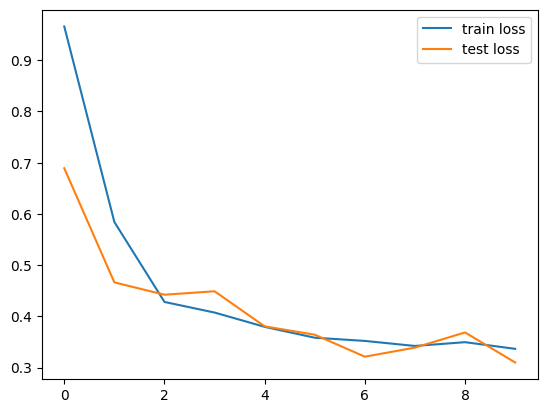

In [ ]:
# Carrega a CNN VGG11 e os pesos treinados com a base Imagenet
backbone3 = models.resnet50()

# Remover a última camada totalmente conectada (classifier)
backbone3 = nn.Sequential(*list(backbone3.children())[:-1])

# Adicionar uma camada de flatten (conversão para vetor)
backbone3.add_module("flatten", nn.Flatten())

# Criar as camadas para classificação
classificador3 = MeuMLP(entrada=2048, camadas_escondidas=[128, 64, 32] , saida=6 )

# instanciar a rede passando o backbone (nossa VGG16) e o classifier
model3 = FineTuningNetwork(backbone=backbone3, classifier=classificador3)

# loss and optimizer
criterion3 = nn.CrossEntropyLoss()
#optimizer3 = torch.optim.Adam(model3.parameters())
optimizer3 = torch.optim.SGD(model3.parameters(),
                                    lr=0.001,
                                    momentum=0.9,
                                    weight_decay=1e-3)

model3.to(device)

# treinar
train_losses, test_losses = fit(model3, criterion3, optimizer3, dataloaders_dict['train'], dataloaders_dict['val'], epochs = 10)
plot_losses(train_losses, test_losses)

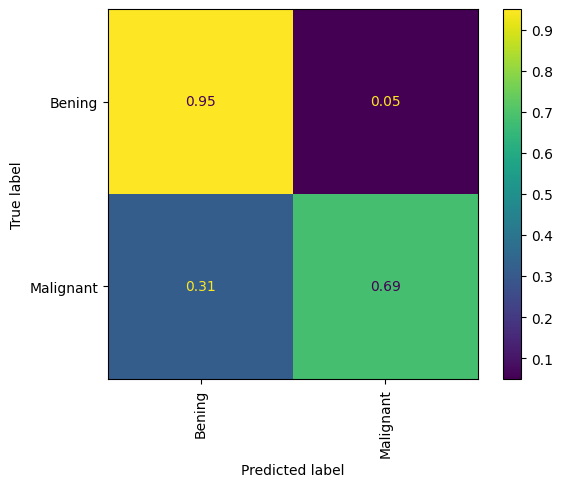

In [ ]:
# Avaliando com o conjunto de teste
predicted, true_labels = predict_module(model3, dataloaders_dict['test'])
#matriz_confusao(true_labels, predicted, ['Buildings', 'Forest', 'Glacier', 'Mountain', 'Sea', 'Street'])
matriz_confusao(true_labels, predicted, ['Bening', 'Malignant'])

# Análise dos resultados
Ambos os modelos foram treinados com a ResNet50, mas com pequenas mudanças nos números de parâmetros das camadas densas e do otimizador.

Dessa forma, dos diferentes testes realizados, foi possível perceber a efetividade da transferência de aprendizado com fine tunning, uma vez que ele obteve resultados muito melhores para a detecção de células malignas. Atingindo uma acurácia intra-classe de 89%, enquanto que o modelo sem finetuning obteve uma acurácia de apenas 69%.